# Drivers at Uber's evening peak, sized by the guesstimate: how many at the peak?

**Week 4, Tuesday, chapter 8, the case's third chapter.** It applies the guesstimate:
clarify, map, calculate, validate (concept notebook 06). On the campus canteen (invented),
notebook 06 built 3,000 x 0.45 x 2 = 2,700 cups, found the share who buy set the range from
1,500 to 3,900, and checked it against the till's 2,340 in the same unit, period and
definition. Notebook 05 left the city head's slide defended against three objections; this
notebook answers the ticket's second question.

**The ticket.** Uber, Hyderabad. Before Thursday's review the city head asks one more
thing: roughly how many drivers must be online at the weekday evening peak to keep the
median rider wait under five minutes, estimated in fifteen minutes and without a dataset.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

**Who needs the answer.** The city head, who will ask the finance partner for incentives
sized on this number; a figure seven times too large pays for drivers the city does not
need, and one too small leaves riders waiting.

**The metric at stake.** Drivers online at one moment of the three-hour weekday evening
peak.

**The questions on the way.**

1. Which number would check the estimate?
2. What does the chain give, and which assumption moves the answer most?
3. What does the trap of a day's trips divided by an hour's cost?
4. Is the estimate sane when checked like for like against the case's own data?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

weeks = pd.read_csv("../data/C2_W04_D02_twelve_weeks_STUDENT.csv")  # the case's twelve zones, week by week
check("twelve weeks in the case's table", len(weeks) == 12)
print(weeks[["week_start", "window", "peak_online_hours", "peak_trips", "rider_requests"]].to_string(index=False))

PASS twelve weeks in the case's table
week_start window  peak_online_hours  peak_trips  rider_requests
2026-07-20 before              19571       36752           41155
2026-07-27 before              19398       37095           41608
2026-08-03 before              19720       37183           41896
2026-08-10 before              19513       37452           42101
2026-08-17 before              19578       37688           42431
2026-08-24 before              20220       38030           42719
2026-08-31  after              23816       39121           43589
2026-09-07  after              24932       39547           43878
2026-09-14  after              24871       39056           43507
2026-09-21  after              24643       38313           42602
2026-09-28  after              24247       37755           41819
2026-10-05  after              23791       37108           41161


## Which number would check the estimate?

Notebook 06's three tests decide it: a check counts the same unit, over the same period,
under the same definition. Four candidates:

| Candidate | What it counts |
|---|---|
| a) Monday's rider requests, 256,556 over six weeks | requests, summed over six weeks, in the case's twelve zones |
| b) A published count of Uber drivers signed up in Hyderabad | sign-ups, at any time |
| c) A published count of Uber drivers online at one weekday evening peak in Hyderabad | drivers online at one moment |
| d) The online driver-hours behind each completed trip in the case's own data, pooled over both daily peak windows | a ratio inside the chain, over a wider period than one evening |

**Predict before you run.** Which candidate passes all three tests?

In [2]:
def is_check(same_unit, same_period, same_definition):
    """Notebook 06's three tests: a check counts the same unit, period and definition as the estimate."""
    return same_unit and same_period and same_definition

candidates = pd.DataFrame({
    "same unit":       [False, True,  True,  False],
    "same period":     [False, False, True,  False],
    "same definition": [False, False, True,  True],
}, index=["a) requests over six weeks", "b) drivers signed up", "c) drivers online at one peak", "d) driver-hours per trip"])
candidates["a check?"] = [is_check(*r) for r in candidates.values]
print(candidates.to_string())
check("only a published count of drivers online at one peak passes all three", candidates["a check?"].sum() == 1
      and candidates["a check?"].iloc[2])

                               same unit  same period  same definition  a check?
a) requests over six weeks         False        False            False     False
b) drivers signed up                True        False            False     False
c) drivers online at one peak       True         True             True      True
d) driver-hours per trip           False        False             True     False
PASS only a published count of drivers online at one peak passes all three


**What happened.** The answer is c, and nobody publishes it: no source checked for this
day holds a count of Uber drivers online at Hyderabad's evening peak, so that slot stays
"to be found". a counts rider requests over six weeks in twelve zones: another unit, a longer
period and a slice of the city. b counts sign-ups, a different definition from drivers
online at one moment. d is not wrong: it checks one link of the chain, a ratio the case's
own data holds over both daily peaks on all seven days, a wider period than one evening, and
when the direct check does not exist that is the honest fallback the afternoon uses.

## What does the chain give, and which assumption moves the answer most?

**Clarify.** One city (the Hyderabad metro area), one platform (Uber) and one product, the
three-hour weekday evening peak, drivers online at one moment, and a median rider wait
under five minutes.

**Map.** Drivers online = (trips to serve in an hour / trips one online driver completes in
an hour) x a buffer. Trips to serve in an hour = people x weekday Uber trips per person x
the share of the day's trips in the evening window / 3 hours; counting trips per person,
never riders, counts a commuter who rides both ways twice. Trips one online driver
completes in an hour = the trips a busy driver fits in an hour x (1 - the idle share), where
the idle share is the share of online drivers with no rider at that moment. The buffer
covers the busiest half hour of the window.

Every value below is a guess said aloud, with the range it could take and the reason beside
it.

**Predict before you run.** If people took 2 weekday Uber trips per 100 instead of 1, what
would happen to the answer?

a) It doubles, to about 11,400
b) It rises by about a quarter
c) It does not change, since the buffer absorbs it
d) It halves

                                                                          why
assumption                                                                   
people in the city                             the metro area, a round number
weekday Uber trips per person                     1 trip for every 100 people
share of trips in the evening                             the evening commute
trips a busy driver fits an hour           a peak trip takes about 25 minutes
idle share                        a guess, from a busy evening to a slack one
buffer for the busiest half hour                     the peak inside the peak
trips an hour: 8,333; drivers online: 5,704; at 2 trips per 100 people: 11,409
                                  lowest  highest
assumption                                       
buffer for the busiest half hour    5500     6200
people in the city                  5100     6300
idle share                          5100     6400
share of trips in the evening       4600     68

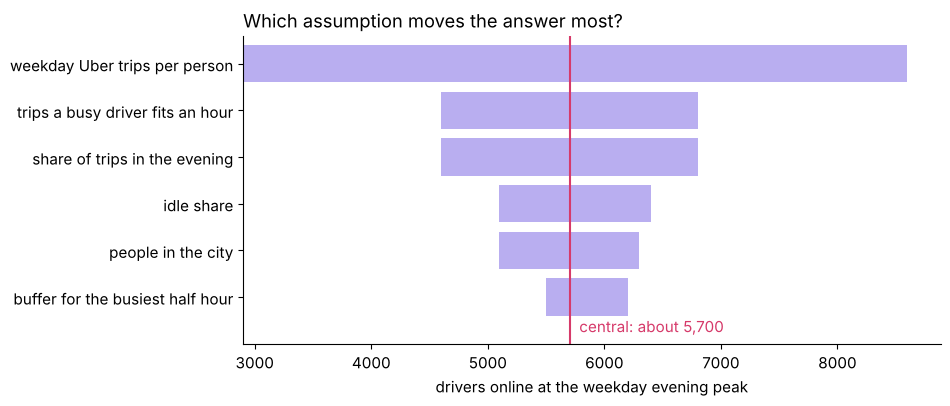

PASS about 5,700 drivers at the central values
PASS doubling trips per person doubles the answer
PASS trips per person moves the answer most


In [3]:
# The ledger: every guess with its range, then the chain run on every version of the ledger.
ledger = pd.DataFrame([   # assumption: central, low, high, and why
    ("people in the city",               10_000_000, 9_000_000, 11_000_000, "the metro area, a round number"),
    ("weekday Uber trips per person",    0.01,       0.005,     0.015,      "1 trip for every 100 people"),
    ("share of trips in the evening",    0.25,       0.20,      0.30,       "the evening commute"),
    ("trips a busy driver fits an hour", 2.4,        2.0,       3.0,        "a peak trip takes about 25 minutes"),
    ("idle share",                       0.30,       0.22,      0.38,       "a guess, from a busy evening to a slack one"),
    ("buffer for the busiest half hour", 1.15,       1.10,      1.25,       "the peak inside the peak"),
], columns=["assumption", "central", "low", "high", "why"]).set_index("assumption")

versions = pd.DataFrame([ledger.central.values], index=["central"], columns=ledger.index)
for name in ledger.index:                       # one row per version: one guess moved to an end
    for end in ("low", "high"):
        versions.loc[f"{name}, {end}"] = ledger.central
        versions.loc[f"{name}, {end}", name] = ledger.loc[name, end]
versions.loc["2 trips per 100 people"] = ledger.central
versions.loc["2 trips per 100 people", "weekday Uber trips per person"] = 0.02

v = versions                                    # the chain, run down every row at once
trips_an_hour = v["people in the city"] * v["weekday Uber trips per person"] * v["share of trips in the evening"] / 3
versions["drivers"] = (trips_an_hour / (v["trips a busy driver fits an hour"] * (1 - v["idle share"]))
                       * v["buffer for the busiest half hour"])
central = versions.loc["central", "drivers"]
doubled = versions.loc["2 trips per 100 people", "drivers"]
ends = pd.DataFrame({end: [versions.loc[f"{name}, {end}", "drivers"] for name in ledger.index]
                     for end in ("low", "high")}, index=ledger.index)
swing = pd.DataFrame({"lowest": ends.min(axis=1), "highest": ends.max(axis=1)}).round(-2).astype(int)
swing["width"] = swing.highest - swing.lowest
swing = swing.sort_values("width")
print(ledger[["why"]])
print(f"trips an hour: {10_000_000 * 0.01 * 0.25 / 3:,.0f}; drivers online: {central:,.0f}; "
      f"at 2 trips per 100 people: {doubled:,.0f}")
print(swing[["lowest", "highest"]])

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(swing.index, swing.width, left=swing.lowest, color=LILAC)
ax.axvline(central, color=ROSE)
ax.set_ylim(-1.0, 5.6)
ax.text(central + 80, -0.75, f"central: about {round(central, -2):,.0f}", color=ROSE)
ax.set_xlabel("drivers online at the weekday evening peak")
ax.set_title("Which assumption moves the answer most?", loc="left")
plt.show()
check("about 5,700 drivers at the central values", round(central, -2) == 5700)
check("doubling trips per person doubles the answer", abs(doubled / central - 2) < 1e-9)
check("trips per person moves the answer most", swing.index[-1] == "weekday Uber trips per person")

**What happened.** The answer is a: the chain is a product, so doubling one factor doubles
the answer, to about 11,400. At the central values, about 8,333 trips an hour divided by
1.68 trips per online driver-hour (2.4 x 0.70), times 1.15, is about 5,700 drivers. Moving
trips per person from 0.5 to 1.5 per 100 moves the answer from about 2,900 to about 8,600
with everything else held, wider than any other assumption; the idle share moves it from
about 5,100 to 6,400.

## What does the trap of a day's trips divided by an hour's cost?

**The plausible wrong answer.** "1 crore people, 1 trip per 100 people, so 1 lakh trips; a
driver does 2.4 trips an hour; so about 41,700 drivers." A city head who takes that to the
review asks for incentives for about seven times the drivers the chain says are needed.

**Predict before you run.** Which step did the hurried chain skip?

a) The buffer for the busiest half hour
b) The day's trips were never brought into an hour of the evening window
c) The people in the city were counted twice
d) None: it is the chain, rounded differently

the hurried chain: 100,000 trips a day / 2.4 an hour = about 41,700 drivers
against the chain's about 5,700: about 7 times as many
PASS the hurried answer is about seven times the chain's


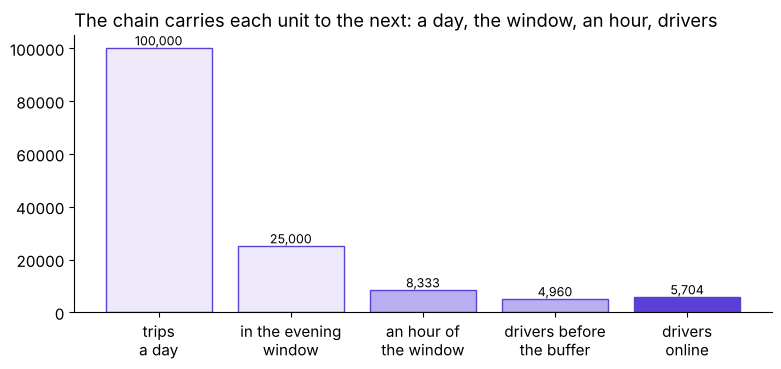

PASS a second route, step by step, reaches the same drivers


In [4]:
day_trips = 10_000_000 * 0.01                          # a day's trips
wrong = day_trips / 2.4                                # divided by an hour's trips per driver
print(f"the hurried chain: {day_trips:,.0f} trips a day / 2.4 an hour = about {round(wrong, -2):,.0f} drivers")
print(f"against the chain's about {round(central, -2):,.0f}: about {wrong / central:.0f} times as many")
check("the hurried answer is about seven times the chain's", 7 < wrong / central < 8)

running = pd.Series({"trips a day": day_trips, "in the evening window": day_trips * 0.25,
                     "an hour of the window": day_trips * 0.25 / 3,
                     "drivers before the buffer": day_trips * 0.25 / 3 / 1.68,
                     "drivers online": day_trips * 0.25 / 3 / (2.4 * 0.7) * 1.15})
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(running.index, running, color=[PALE, PALE, LILAC, LILAC, VIOLET], edgecolor=VIOLET)
ax.bar_label(bars, labels=[f"{x:,.0f}" for x in running], fontsize=9)
ax.set_xticks(range(5), ["trips\na day", "in the evening\nwindow", "an hour of\nthe window",
                         "drivers before\nthe buffer", "drivers\nonline"])
ax.set_title("The chain carries each unit to the next: a day, the window, an hour, drivers", loc="left")
plt.show()
check("a second route, step by step, reaches the same drivers", abs(running.iloc[-1] - central) < 1e-6)

**Why it is wrong.** The answer is b. A day's trips were divided by an hour's trips per
driver: a period mismatch, and the idle share and the buffer were skipped as well. **The check:**
write the unit beside every factor. **The fix:** bring the day's trips into the evening
window's hour before dividing. The step-by-step chain above is a second route to the same
5,700, and it agrees with the vectorised chain to the driver.

## Is the estimate sane when checked like for like against the case's own data?

**Validate.** Monday's tables are a slice of the city, the twelve zones the enrolled drivers
work, so their absolute count cannot check a city total. Monday's data counts peak hours on
all seven days, two three-hour windows a day, 42 hours a week, so its 256,556 after-window
requests are about 1,018 an hour, far below the city's 8,333 trips. What the slice can
check is a ratio in the middle of the chain, counted the same way on both sides: online
driver-hours per completed trip.

        peak_online_hours  peak_trips  driver_hours_per_trip
window                                                      
before             118000      224200                   0.53
after              146300      230900                   0.63
the chain: 0.60 driver-hours per trip before its buffer, 1.13 times the case's before window
re-run at the case's 1.90 trips an hour: about 5,000 drivers
PASS the chain runs high, by about an eighth


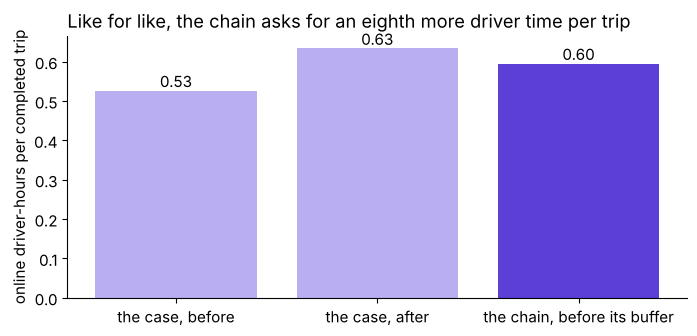

per day: 300 million; over 31 days: 290 million (-3.2%)
PASS the per-day figure divides by the month's own days


In [5]:
# Check the chain like for like against the case's driver-hours per trip, then a month's own days.
case = weeks.groupby("window")[["peak_online_hours", "peak_trips"]].sum().loc[["before", "after"]]
per_trip = case.peak_online_hours / case.peak_trips          # online driver-hours per completed trip
case["driver_hours_per_trip"] = per_trip.round(2)
chain = 1 / (2.4 * (1 - 0.30))
case_tph_before = 1 / per_trip["before"]
checked = 10_000_000 * 0.01 * 0.25 / 3 / case_tph_before * 1.15
print(case)
print(f"the chain: {chain:.2f} driver-hours per trip before its buffer, "
      f"{chain / per_trip['before']:.2f} times the case's before window")
print(f"re-run at the case's {case_tph_before:.2f} trips an hour: about {round(checked, -2):,.0f} drivers")
check("the chain runs high, by about an eighth", 1.1 < chain / per_trip["before"] < 1.15)

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.bar(["the case, before", "the case, after", "the chain, before its buffer"],
              [per_trip["before"], per_trip["after"], chain], color=[LILAC, LILAC, VIOLET])
ax.bar_label(bars, fmt="%.2f")
ax.set_ylabel("online driver-hours per completed trip")
ax.set_title("Like for like, the chain asks for an eighth more driver time per trip", loc="left")
plt.show()

month_total, days = 9e9, 30                 # an invented payments network: 9 billion in a 30-day month
per_day, over_31 = month_total / days, month_total / 31
print(f"per day: {per_day / 1e6:,.0f} million; over 31 days: {over_31 / 1e6:,.0f} million "
      f"({over_31 / per_day - 1:+.1%})")
check("the per-day figure divides by the month's own days", round(per_day / 1e6) == 300)

**What happened.** Before the launch the case's twelve zones used 0.53 online driver-hours
per completed trip, with a median wait of 4.8 minutes; after it, 0.63. The chain puts 0.60
behind each trip before its buffer, about an eighth more than the window whose wait met the
target, so the chain errs high. Re-run at the case's 1.90 trips an hour it gives about
5,000 drivers, so the honest answer is about 5,000 to 5,700. The invented network shows the
per-day check: 9 billion over its 30 days is 300 million a day, and dividing by 31 gives
290 million, 3.2 percent low for no reason but the calendar. The afternoon's paired drill
on UPI meets the published figure only after the pairs have swapped sheets and checked each
other's chain.

**The answers, one line each.**

1. Only a published count of drivers online at one peak would check the estimate directly,
   and none has been found; the case's driver-hours per trip checks one link.
2. About 5,700 drivers before the check, from about 2,900 to 8,600 with everything else
   held, driven by trips per person.
3. A day's trips over an hour's rate gives about 41,700, about seven times too many.
4. Like for like, the chain's 0.60 driver-hours per trip runs an eighth above the case's
   0.53, so say about 5,000 to 5,700.

### What will an interviewer ask about this, and what does a strong answer do?

**[S] How many drivers must be online at the evening peak?** Clarify the city, the product,
the window, the unit (online at one moment) and the wait target; say the formula; say each
assumption aloud with its range; give the range with everything else held and the factor
that drives it; check the ratio like for like and move the answer if the check says so; and
say what the number decides.

**The AI-company variant.** The same four steps size an AI company's number: how many
requests a second a chatbot must serve at its evening peak. Clarify one product, one region,
and whether the number is requests a second or requests in flight at one moment, since
requests in flight are requests a second times the seconds each takes to answer. Map daily
users x requests per user x the evening's share, divided by the seconds in the window, which
gives the window's average second, then times a buffer for the busiest minute, which gives
the peak. Calculate each factor aloud with its range. Validate like for like: the average
against last month's average second over the same evening window in the serving logs, and
the peak against last month's busiest minute.